In [1]:
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import os
import yaml

In [3]:
#Load the configuration file
with open("../config/config.yaml", "r") as f:
    config = yaml.safe_load(f)

raw_data_path = "../"+config["paths"]["raw_data_dir"]   
notebook_ver = "1.2"
sample_size = 1000000
# Leave as an asterix if you want all the subreddits
subreddit = "datascience"

## Sampling the data

I will sample the data to make it light in resources, as the original dataset is fairly large.

In [3]:
# Retrieve the path and file names for all the parquet files

def get_parquet_from_path(path):
    parquet_files = []
    for (dir_path, _, files) in os.walk(path):
        for f in files:
            if f.endswith(".parquet"):
                parquet_files.append(os.path.join(dir_path, f)) 
    return parquet_files

In [4]:
# Check the method get_parquet_from_path() output

file_path = get_parquet_from_path(raw_data_path)
(print(file_path))


['../data/raw/cybersecurity_submissions.parquet', '../data/raw/QualityAssurance_comments.parquet', '../data/raw/dataengineering_comments.parquet', '../data/raw/datascience_submissions.parquet', '../data/raw/dataengineering_submissions.parquet', '../data/raw/SoftwareEngineering_submissions.parquet', '../data/raw/QualityAssurance_submissions.parquet', '../data/raw/datascience_comments.parquet', '../data/raw/SoftwareEngineering_comments.parquet', '../data/raw/cscareerquestionsEU_comments.parquet', '../data/raw/cscareerquestions_submissions.parquet', '../data/raw/cscareerquestionsEU_submissions.parquet', '../data/raw/cscareerquestions_comments.parquet', '../data/raw/cybersecurity_comments.parquet']


### Core Sampler

In [5]:
import json
import random
def sample_parquet_file_to_json(file_path, desired_samples = 30000):
    file_count = 0
    for file_number in range(len(file_path)):
        file_name = os.path.splitext(os.path.basename(file_path[file_number]))[0]
        # Read the paraquet file metadata
        metadata = pq.read_metadata(file_path[file_number])
        # Total number of samples and target retention number
        total_samples = metadata.num_rows
        # Perform random sampling
        if total_samples <= desired_samples:
            table = pq.read_table(file_path[file_number])
            selected_samples = table.to_pylist()
        else:
            random_indices = random.sample(range(total_samples), desired_samples)
            random_indices.sort()  # Sort the indices to speed up batch reading
            table = pq.read_table(file_path[file_number])
          
            # Take a batch based on the random  indices
            sampled_table = table.take(random_indices)
            selected_samples = sampled_table.to_pylist()
        # Write the sampled results to a new JSON file
        output_dir_path = (f"../data/samples/{notebook_ver}")
        os.makedirs(output_dir_path, exist_ok=True)
        with open(f'{output_dir_path}/{file_name}.json','w', encoding='utf-8') as f:
            json.dump(selected_samples, f, ensure_ascii=False, indent=4, default=str)
        print(f"Random sampling completed for {file_name}, retained {len(selected_samples)} samples.") 
        file_count+=1
    print(f"Done! Sampled {file_count} files")   

In [11]:
# Use the desired_samples in case you don't want the default 30k
sample_parquet_file_to_json(file_path, desired_samples = sample_size)

Random sampling completed for cybersecurity_submissions, retained 64467 samples.
Random sampling completed for QualityAssurance_comments, retained 64116 samples.
Random sampling completed for dataengineering_comments, retained 144386 samples.
Random sampling completed for datascience_submissions, retained 45302 samples.
Random sampling completed for dataengineering_submissions, retained 15044 samples.
Random sampling completed for SoftwareEngineering_submissions, retained 10301 samples.
Random sampling completed for QualityAssurance_submissions, retained 9565 samples.
Random sampling completed for datascience_comments, retained 604557 samples.
Random sampling completed for SoftwareEngineering_comments, retained 41518 samples.
Random sampling completed for cscareerquestionsEU_comments, retained 229721 samples.
Random sampling completed for cscareerquestions_submissions, retained 239975 samples.
Random sampling completed for cscareerquestionsEU_submissions, retained 13865 samples.
Random

## Cleaning the Data

### Removing Code Blocks

In [4]:
import re

# Needs to be integrated to be done before the json_to_df method as 
# text need to be cleaned before going into a df

def clean_code_snippets(text):
    # 1. Remove multi-line code blocks (``` ... ```)
    # Replaces everything from the first ``` to the next ```, including newlines.
    # [^`]*? ensures we match non-greedily.
    no_blocks = re.sub(r'```[^`]*?```', '', text)
    
    # 2. Remove inline code blocks (` ... `)
    # Replaces everything between single backticks non-greedily.
    clean_text = re.sub(r'`[^`]+?`', '', no_blocks)
    
    return clean_text

### Data sanitization and normalization

In [5]:
from pathlib import Path

data_samples_path = Path("../"+config["paths"]["data_samples_dir"]+ f"/{notebook_ver}")

                         
# Note this Method is different from the regular one as it take the subreddit name 
# And only output the dataframe for a single subreddit in one type e.g. comments or submissions
def json_to_df(json_path, subreddit, dataset_type = "submissions", lines = False):
    try:
        json_path = Path(json_path)
        valid_dataset_type = ["submissions", "comments"]
        if dataset_type not in valid_dataset_type:
            raise ValueError(f"Invalid type for the parameter. Choose from {valid_dataset_type}")

        # Load the json files into a dataframe and add a coulmn that says what subreddit
        # the comment or submission belong to.
                         
        #***************************************************************************                 
        # In this Notebook version we will keep each subreddit in a separate dataset
        #***************************************************************************                 
                         
    
        tmp_files_list = []  

        selected_files = [file for file in json_path.glob(f"{subreddit}_{dataset_type}.json") if file.is_file()]
        if len(selected_files) <= 0:
            raise FileNotFoundError()
            
        for file_path in selected_files:
            tmp_file = pd.read_json(file_path, lines = lines)
            tmp_file["subreddit"] = file_path.stem.split("_")[0]
            tmp_files_list.append(tmp_file)

        files_df = pd.concat(tmp_files_list, ignore_index = True)
        return files_df 
    except FileNotFoundError as e:
        print(f"No files found at the current path: {str(json_path)}")
    except ValueError as e:
        print(e)
 

**Draw a plot to see the total amount of data in each subreddit**

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load your master submissions DataFrame using your function
dataset_type = "comments"
data_df = json_to_df(data_samples_path,dataset_type)

# 2. Count the submissions per subreddit and sort them in descending order
# Sorting ensures the chart has a clean visual hierarchy!
subreddit_counts = data_df['subreddit'].value_counts().reset_index()
subreddit_counts.columns = ['subreddit', dataset_type+'_count']

# 3. Create the plot using subplots (avoids using .figure())
fig, ax = plt.subplots(figsize=(10, 5))

# 4. Draw the horizontal bar chart
sns.barplot(
    data=subreddit_counts,
    x= dataset_type+'_count',
    y='subreddit',
    ax=ax,
    palette='viridis',
    hue='subreddit',
    legend=False
)

# 5. Clean up typography and ensure labels are highly readable
ax.set_title(f'Total Amount of {dataset_type} per Subreddit', fontsize=14, pad=15, fontweight='bold')
ax.set_xlabel(f'Number of {dataset_type}', fontsize=12, labelpad=10)
ax.set_ylabel('Subreddit', fontsize=12, labelpad=10)

# Adjust layout automatically so labels are never clipped or truncated
plt.tight_layout()

No files found at the current path: ../data/samples/1.2


TypeError: 'NoneType' object is not subscriptable

In [7]:
submission_df = json_to_df(data_samples_path, subreddit, "submissions")
comment_df = json_to_df(data_samples_path, subreddit, "comments")

comment_df.isnull().sum()

id             0
subreddit      0
created_utc    0
score          0
text           0
dtype: int64

**Data Cleaning**

In [8]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
print("Done Loading Stop words")
def has_missing_body(sample):
    return 'body' not in sample
def clean_text(text):
    # Data cleaning: remove special symbols and links
    text = re.sub(r'http\S+', '', text) # Remove links
    text = re.sub(r'\W+', ' ', text) # Remove special symbols
    return text

def preprocess_text(text):
    # Text preprocessing: convert to lowercase, remove punctuation, and numbers
    text = text.lower()
    text = re.sub(r'\d+', '', text) # Remove numbers
    #text = re.sub(r'[^\w\s]', '', text) # Remove punctuation
    return text

def tokenize_text(text):
    # Text tokenization: split the text by space
    return text.split()

def remove_stopwords(words_list):
    # Stopwords handling: remove stopwords
    stop_words = set(stopwords.words('english'))
    return [word for word in words_list if word.lower() not in
    stop_words]
    
def remove_short_words(words_list):
    # Remove words with length less than or equal to 2
    return [word for word in words_list if len(word) > 2]

def reassemble_text(text):
    sentence = " ".join(text)
    return sentence
    

Done Loading Stop words


[nltk_data] Downloading package stopwords to /home/bruh/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


**Processing Pipeline**

In [9]:
def process_pipeline(text):
    processed = text
    processed = clean_code_snippets(processed)
    processed = clean_text(processed)
    #processed = preprocess_text(processed)
    #processed = tokenize_text(processed)
    #processed = remove_stopwords(processed)
    #processed = remove_short_words(processed)
    #processed = reassemble_text(processed)
    return processed

**Applying the processing pipeline**

In [10]:
submission_df["cleaned_text"] = submission_df['text'].apply(process_pipeline)
comment_df["cleaned_text"] = comment_df['text'].apply(process_pipeline)

In [11]:
submission_df["cleaned_text"].head(5)
comment_df["cleaned_text"].head(5)

0                                       Try r datasets
1    Also try r opendata r opendata Many government...
2    Interesting stuff Do you know of any success s...
3     Recollect is an application that uses geograp...
4                               look into buzzdata too
Name: cleaned_text, dtype: object

**Word Frequency Chart**

**CAREFULL!!!! resource heavy plot if the sample size is too large**

In [11]:
                                                                           
from collections import Counter                                          
import matplotlib.pyplot as plt                                          
import pandas as pd                                                      
import seaborn as sns                                                    
                                                                         
# 1. Flatten the list of tokens from all rows in the cleaned column  (splitting the strings)                                                    
submission_words = [word for text in submission_df["cleaned_text"].dropna() for word in text.split()]                                                                        
comment_words = [word for text in comment_df["cleaned_text"].dropna() for word in text.split()]                                                              
                                                                   
all_words = submission_words + comment_words                             
                                                                         
# 2. Extract the top 20 most common words                                
top_n = 20                                                               
word_counts = Counter(all_words).most_common(top_n)                      
                                                                         
# 3. Convert to a DataFrame for easier plotting with Seaborn             
word_freq_df = pd.DataFrame(word_counts, columns=["Word", "Frequency"])  
                                                                         
# 4. Ensure the bars are in sorted descending order for visual hierarchy 
word_freq_df = word_freq_df.sort_values(by="Frequency", ascending=False) 
                                                                         
# 5. Create the plot using subplots                                      
fig, ax = plt.subplots(figsize=(10, 6))                                  
                                                                         
# 6. Draw a horizontal bar chart                                         
sns.barplot(                                                             
        data=word_freq_df,                                                   
        x="Frequency",                                                       
        y="Word",                                                            
        ax=ax,                                                               
        palette="viridis",
        hue="Word",
        legend=False,
    )
  
    # 7. Clean up typography and labels
ax.set_title(
    f"Top {top_n} Most Frequent Words", fontsize=14, pad=15,
      fontweight="bold"
)
ax.set_xlabel("Frequency", fontsize=12, labelpad=10)
ax.set_ylabel("Word", fontsize=12, labelpad=10)

# 8. Adjust layout
plt.tight_layout()


KeyboardInterrupt: 

### Vectorizing the Data

**Note:** The analysis and BERTopic models both need to be revised and fine tuned to 
be as effective as possible.\
Their results need to make sense as they currently don't.

In [22]:
import pandas as pd
import numpy as np
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
nltk.download('vader_lexicon')


df = submission_df.copy()

df['created_utc'] = pd.to_datetime(df['created_utc'])



# Pre-calculate embeddings
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedding_model.encode(df["text"].dropna().astype(str).to_list(), show_progress_bar=True)

# Preventing Stochastic Behavior
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=42)

# Controlling Number of Topics
hdbscan_model = HDBSCAN(min_cluster_size=100, metric='euclidean', cluster_selection_method='eom', prediction_data=True)

# Improving Default representation
vectorizer_model = CountVectorizer(stop_words = "english", min_df = 2, ngram_range = (1, 2))

topic_model = BERTopic(

  # Pipeline models
  embedding_model=embedding_model,
  umap_model=umap_model,
  hdbscan_model=hdbscan_model,
  vectorizer_model=vectorizer_model,
    
  # Hyperparameters
  top_n_words=10,
  verbose=True
)

topics, probs = topic_model.fit_transform(df["cleaned_text"])
print("Done!")

df["bertopic_id"] = topics

print("Calculating VADER sentiment...")
sia = SentimentIntensityAnalyzer()
df['vader_sentiment'] = df['text'].apply(lambda x: sia.polarity_scores(str(x))['compound'])
print("Done!")

#Convert the timestamp column to datetime
df['datetime'] = pd.to_datetime(df['created_utc'], unit='s') # or unit='ms' depending on your data

# Grouping the VADER score with BERTopic IDs
bt_sentiment = df.groupby('bertopic_id')['vader_sentiment'].mean().reset_index()
print("Done!!!")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/bruh/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
Batches: 100%|█████████████████████████| 1416/1416 [01:08<00:00, 20.63it/s]
2026-07-24 23:42:35,748 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|█████████████████████████| 1416/1416 [01:10<00:00, 20.18it/s]
2026-07-24 23:43:46,072 - BERTopic - Embedding - Completed ✓
2026-07-24 23:43:46,073 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-07-24 23:44:12,247 - BERTopic - Dimensionality - Completed ✓
2026-07-24 23:44:12,249 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-07-24 23:44:16,973 - BERTopic - Cluster - Completed ✓
2026-07-24 23:44:16,980 - BERTopic - Representation - Extracting topics from clusters using representation models.
2026-07-24 23:44:20,420 - BERTopic - Representation - Completed ✓


Done!
Calculating VADER sentiment...
Done!
Done!!!


<Axes: title={'center': 'Sentiment Evolution Over Time'}, xlabel='datetime'>

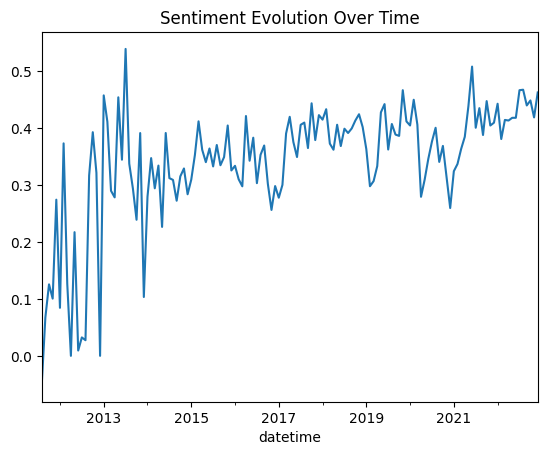

In [23]:
# Resample/Group by week or month to track evolution over time
temporal_sentiment = df.groupby(df['datetime'].dt.to_period('M'))['vader_sentiment'].mean()

# Plot it
temporal_sentiment.plot(kind='line', title='Sentiment Evolution Over Time')

In [24]:
df['vader_sentiment'].describe()

count    45302.000000
mean         0.388833
std          0.469244
min         -0.997900
25%          0.000000
50%          0.440400
75%          0.850400
max          1.000000
Name: vader_sentiment, dtype: float64

### Results Exploration

In [25]:
# View a summary table of all top topics, their sizes, and keyword names
topic_info = topic_model.get_topic_info()
print(topic_info.head(10))

# Get a detailed look at words defining a specific topic (e.g., Topic 0)
print(topic_model.get_topic(0))

   Topic  Count                                               Name  \
0     -1  21909                  -1_data_science_data science_like   
1      0   2473                    0_science_data_data science_job   
2      1   1544                    1_time series_series_time_model   
3      2   1383                2_model_regression_features_feature   
4      3   1290                       3_text_nlp_sentiment_twitter   
5      4   1160               4_deep_deep learning_neural_learning   
6      5    815                  5_python_language_learn_languages   
7      6    795  6_visualization_data visualization_plot_matplo...   
8      7    759  7_interview_questions_interviews_interview que...   
9      8    611                             8_aws_cloud_file_files   

                                      Representation  \
0  [data, science, data science, like, work, job,...   
1  [science, data, data science, job, degree, mas...   
2  [time series, series, time, model, sales, fore...   
3  [m

20it [00:19,  1.03it/s]


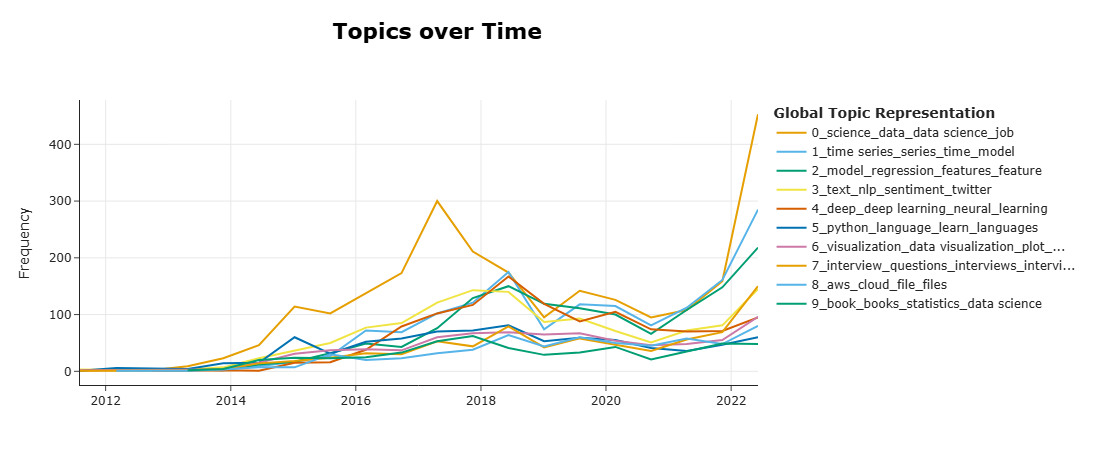

In [26]:
# Extract timestamps into a list matching the document ordering
timestamps = df['created_utc'].tolist()

# Compute the topic frequencies and representations across your time intervals
topics_over_time = topic_model.topics_over_time(df["cleaned_text"], timestamps, nr_bins=20)

# Visualize the dynamic evolution interactively
topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10)

**Experimental Plot 1**

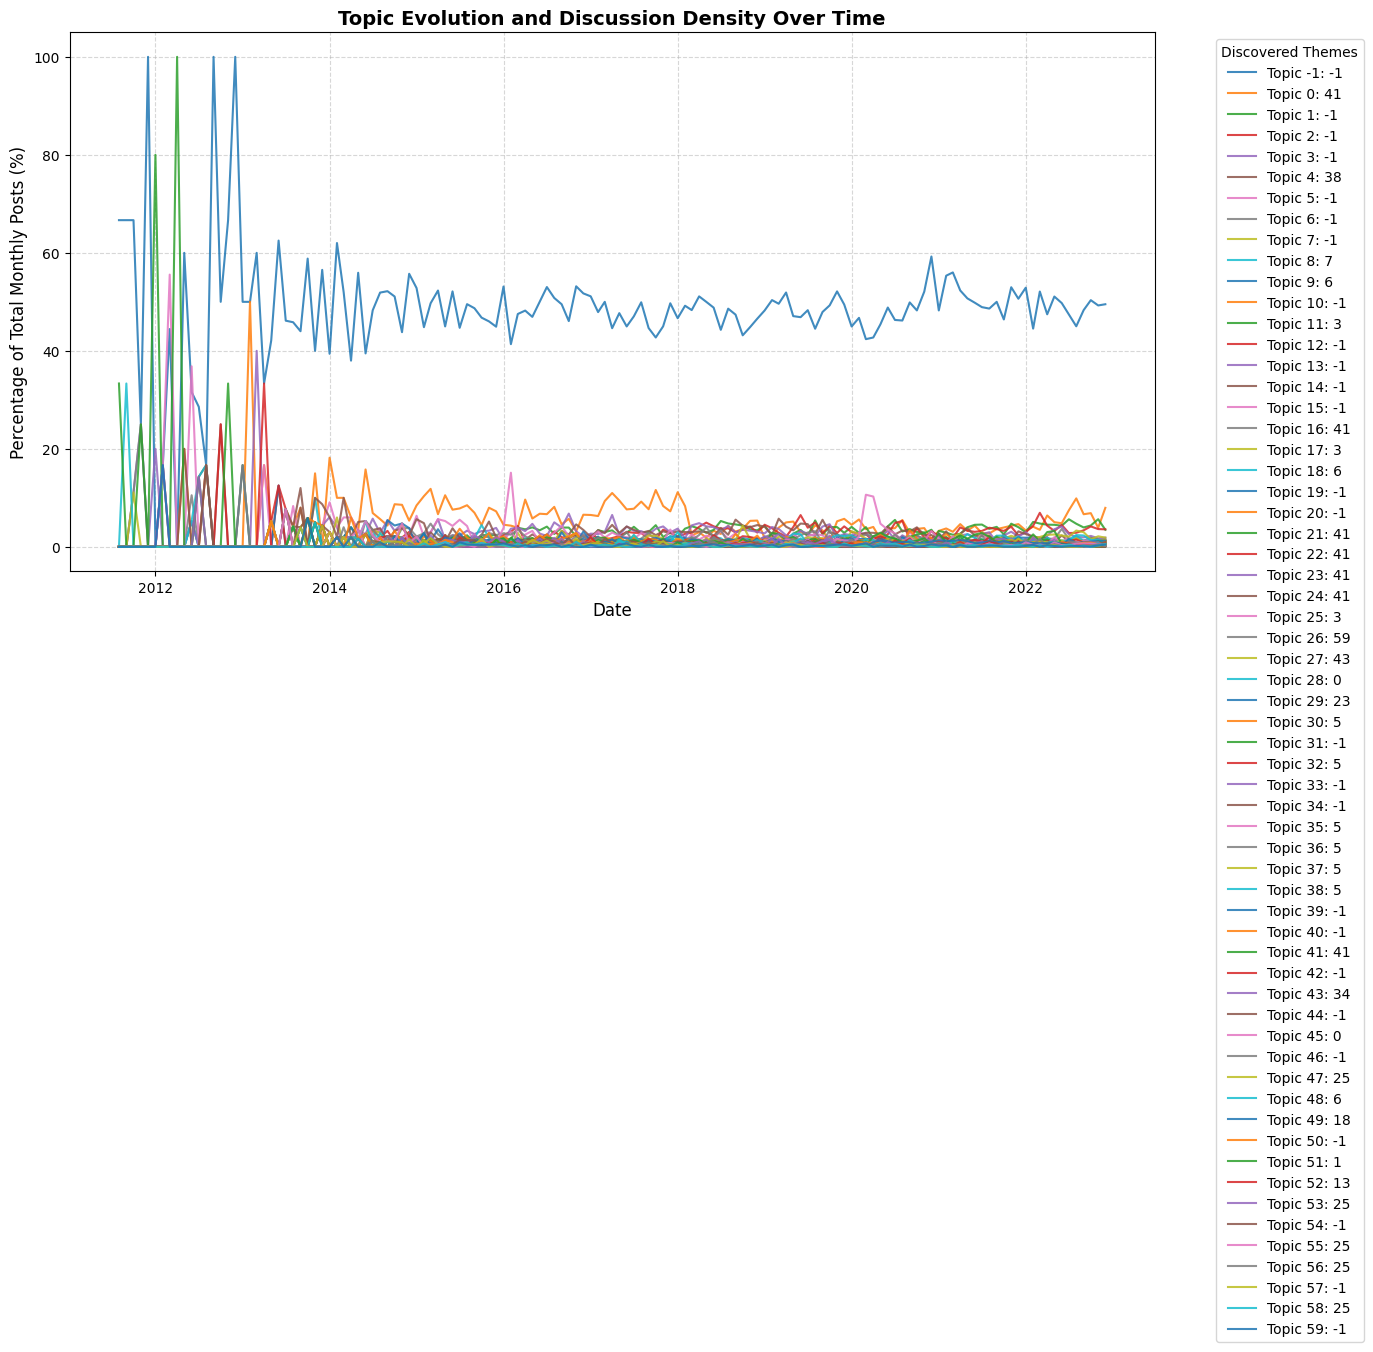

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Plot the Topic Evolution Over Time

# 1. Group by month and topic, then count how many posts belong to each topic
monthly_topics = df.groupby([df['created_utc'].dt.to_period('M'), 'bertopic_id']).size().unstack(fill_value=0)

# 2. Convert raw counts to percentages per month so volume spikes don't distort the trend
monthly_trends_pct = monthly_topics.div(monthly_topics.sum(axis=1), axis=0) * 100

# 3. Plot the temporal evolution
plt.figure(figsize=(14, 7))

for topic_id in monthly_trends_pct.columns:
    # Use the top keywords as the line label in our legend
    label_name = f"Topic {topic_id}: {topics[topic_id]}"
    plt.plot(monthly_trends_pct.index.to_timestamp(), monthly_trends_pct[topic_id], label=label_name, alpha=0.85)

# Styling and Details
plt.title("Topic Evolution and Discussion Density Over Time", fontsize=14, fontweight='bold')
plt.ylabel("Percentage of Total Monthly Posts (%)", fontsize=12)
plt.xlabel("Date", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title="Discovered Themes", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

**Experimental Plot 2**

/tmp/ipykernel_1304/899303856.py:32: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('viridis', num_topics)(range(num_topics))


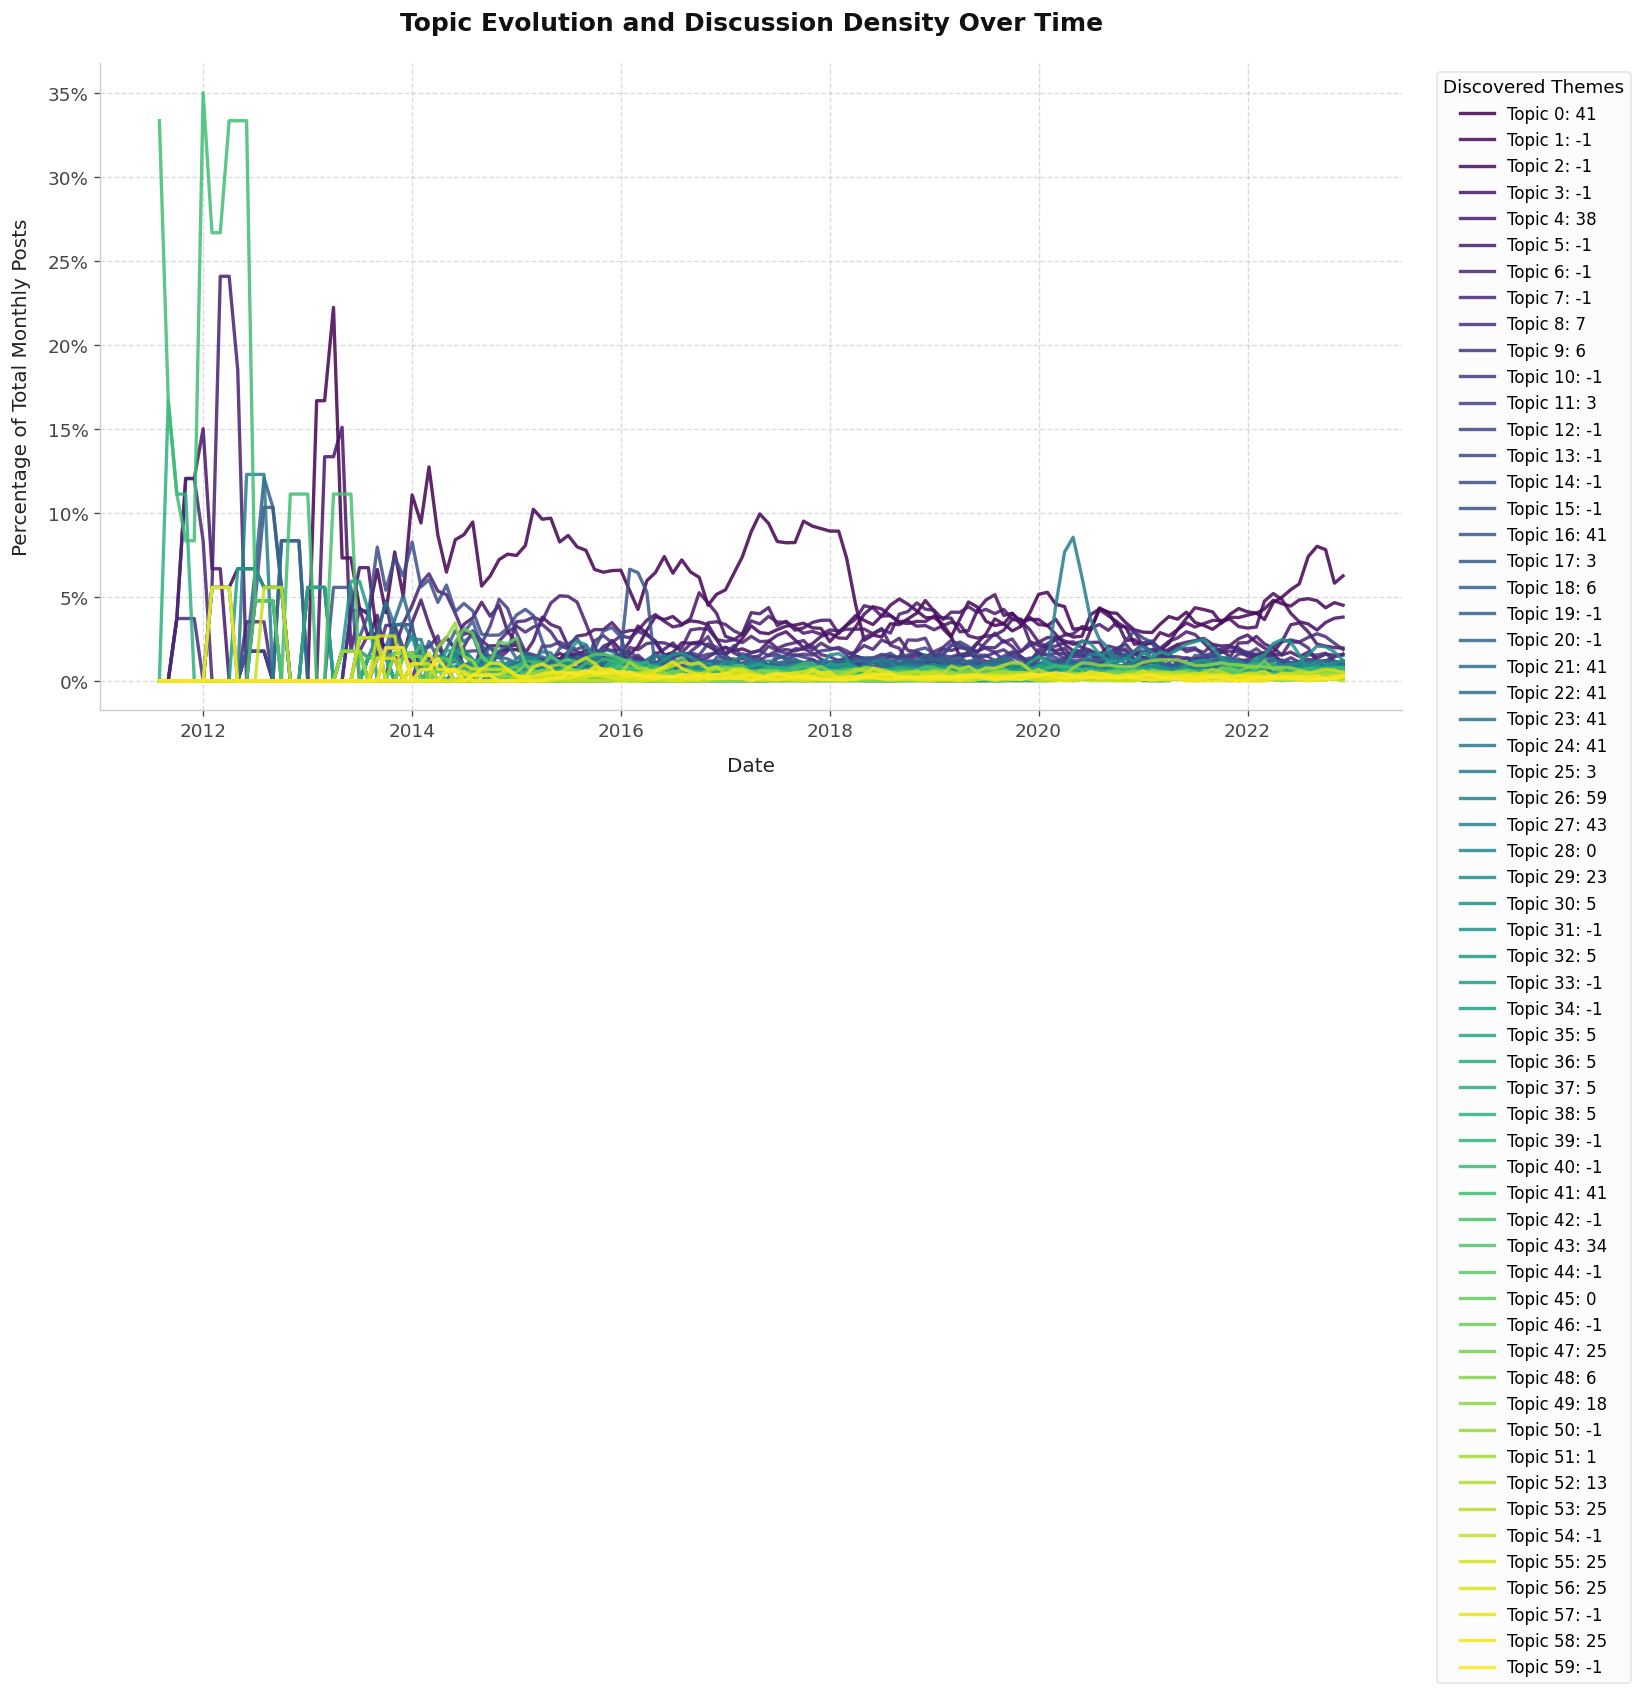

In [28]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# 1. Group by month and BERTopic ID, unstack, and convert to monthly percentages
# (Replaced 'topic_id' with 'bertopic_id' for your new model)
monthly_topics = df.groupby([df['created_utc'].dt.to_period('M'), 'bertopic_id']).size().unstack(fill_value=0)
monthly_trends_pct = monthly_topics.div(monthly_topics.sum(axis=1), axis=0) * 100

# Convert index to standard timestamps for Matplotlib
plot_data = monthly_trends_pct.copy()
plot_data.index = plot_data.index.to_timestamp()

# 2. Smooth the data using a 3-month rolling average to eliminate harsh jagged noise
smoothed_data = plot_data.rolling(window=3, min_periods=1).mean()

# === NEW: DROP TOPIC -1 OUTLIERS ===
# This keeps the huge outlier bin from flattening out or skewing your actual trend lines
if -1 in smoothed_data.columns:
    smoothed_data = smoothed_data.drop(columns=[-1])

# 3. Initialize the clean visual frame
fig, ax = plt.subplots(figsize=(14, 7), dpi=120)

# === UPDATED: DYNAMIC COLOR PALETTE ===
# Count how many clean topics are left to display
num_topics = len(smoothed_data.columns)

# 'tab20' handles up to 20 topics seamlessly; viridis handles even larger sets smoothly
if num_topics <= 20:
    colors = plt.cm.tab20(range(num_topics))
else:
    colors = plt.cm.get_cmap('viridis', num_topics)(range(num_topics))

# 4. Plot each topic line
# Using 'enumerate' ensures the color index matches seamlessly from 0 to num_topics
for i, topic_id in enumerate(smoothed_data.columns):
    label_name = f"Topic {topic_id}: {topics[topic_id]}"
    ax.plot(
        smoothed_data.index, 
        smoothed_data[topic_id], 
        label=label_name, 
        color=colors[i], 
        linewidth=2, 
        alpha=0.85
    )

# 5. Apply "Minimalist" Styling
ax.spines['top'].set_visible(False)     # Remove top spine
ax.spines['right'].set_visible(False)   # Remove right spine
ax.spines['left'].set_color('#cccccc')   # Soften left spine
ax.spines['bottom'].set_color('#cccccc') # Soften bottom spine

# Clean up ticks and gridlines
ax.tick_params(colors='#444444', labelsize=11)
ax.grid(True, linestyle='--', alpha=0.3, color='#888888')

# Append '%' directly to the Y-axis labels
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

# 6. Set clean, professional typography
ax.set_title("Topic Evolution and Discussion Density Over Time", fontsize=15, fontweight='bold', pad=20, color='#111111')
ax.set_ylabel("Percentage of Total Monthly Posts", fontsize=12, labelpad=10, color='#222222')
ax.set_xlabel("Date", fontsize=12, labelpad=10, color='#222222')

# Place the legend neatly to the right
ax.legend(
    title="Discovered Themes", 
    title_fontsize='11',
    fontsize='10',
    bbox_to_anchor=(1.02, 1), 
    loc='upper left', 
    frameon=True,
    facecolor='#fcfcfc',
    edgecolor='#e0e0e0'
)

plt.tight_layout()
plt.show()